In [ ]:
text = "The quick brown foxes  are jumping over the lazy dogs while running fast"

# 1. Stop words set
stop_words = {"the", "a", "an", "is", "are", "while", "over", "in", "on", "at", "to"}

# 2. Tokenization & Lowercasing
tokens = text.lower().split()

# 3. Stop Word Removal
filtered_tokens = [word for word in tokens if word not in stop_words]

# 4. Pure Python Suffix-Based Stemmer (Replaces NLTK PorterStemmer)
def simple_stemmer(word):
    suffixes = ['ing', 'es', 's', 'ed', 'ly', 'er']
    for suffix in suffixes:
        if word.endswith(suffix) and len(word) > len(suffix) + 2:
            return word[:-len(suffix)]
    return word

stemmed_tokens = [simple_stemmer(word) for word in filtered_tokens]

print("Original Tokens :", tokens)
print("After StopWords :", filtered_tokens)
print("After Stemming  :", stemmed_tokens)

Original Tokens : ['the', 'quick', 'brown', 'foxes', 'cried', 'are', 'jumping', 'over', 'the', 'lazy', 'dogs', 'while', 'running', 'fast']
After StopWords : ['quick', 'brown', 'foxes', 'cried', 'jumping', 'lazy', 'dogs', 'running', 'fast']
After Stemming  : ['quick', 'brown', 'fox', 'cri', 'jump', 'lazy', 'dog', 'runn', 'fast']


In [ ]:
# Collection of documents
documents = {
    "Doc1": "heart disease patient health",
    "Doc2": "disease treatment patient doctor",
    "Doc3": "heart health doctor lifestyle"
}

# 1. Build Inverted Index (Term -> Set of Doc IDs)
inverted_index = {}
for doc_id, text in documents.items():
    for word in text.lower().split():
        inverted_index.setdefault(word, set()).add(doc_id)

# Print Inverted Index
print("--- INVERTED INDEX ---")
for word, doc_ids in sorted(inverted_index.items()):
    print(f"{word} -> {sorted(list(doc_ids))}")

# 2. Document Retrieval (Query: "heart disease")
query = "heart disease".lower().split()
##query = input("\nEnter search query: ").lower().split()
results = set(documents.keys())

for word in query:
    results = results.intersection(inverted_index.get(word, set()))

print(f"\nRetrieved Documents for '{' '.join(query)}':", sorted(list(results)))

--- INVERTED INDEX ---
disease -> ['Doc1', 'Doc2']
doctor -> ['Doc2', 'Doc3']
health -> ['Doc1', 'Doc3']
heart -> ['Doc1', 'Doc3']
lifestyle -> ['Doc3']
patient -> ['Doc1', 'Doc2']
treatment -> ['Doc2']

Retrieved Documents for 'doctor health': ['Doc3']


In [6]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB

# 1. Load Dataset (Colab upload or Jupyter local path)
try:
    from google.colab import files
    df = pd.read_csv(list(files.upload().keys())[0])
except ImportError:
    df = pd.read_csv("heart.csv")

# 2. Extract key features & binarize continuous values
X = df[["age", "sex", "cp", "chol"]].copy()
X["age"] = (X["age"] > 50).astype(int)
X["chol"] = (X["chol"] > 240).astype(int)
y = (df["target"] > 0).astype(int)

# 3. Construct Bayesian Model & Train
model = CategoricalNB()
model.fit(X, y)

# 4. Predict Diagnosis for Sample Patient [Age>50, Male, High ChestPain, High Chol]
patient = [[1, 1, 2, 1]]
probs = model.predict_proba(patient)[0]

print("No Disease Prob :", round(probs[0], 4))
print("Disease Prob    :", round(probs[1], 4))
print("Diagnosis       :", "Heart Disease" if model.predict(patient)[0] == 1 else "Normal")

No Disease Prob : 0.1505
Disease Prob    : 0.8495
Diagnosis       : Heart Disease


c:\Users\prasa\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
c:\Users\prasa\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


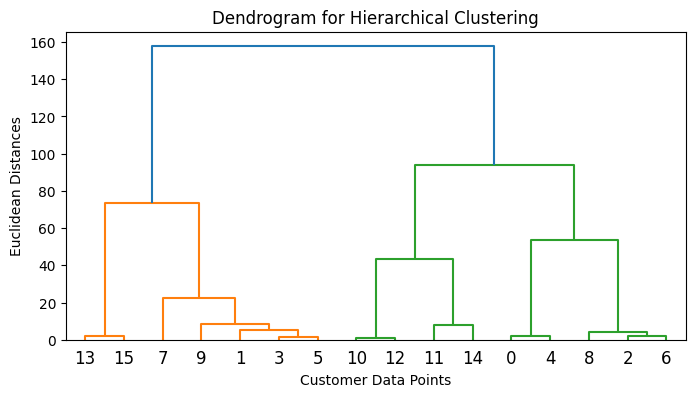

--- CLUSTER ASSIGNMENTS ---
    CustomerID  Annual_Income  Spending_Score  Cluster
0            1             15              39        1
1            2             15              81        0
2            3             16               6        1
3            4             16              77        0
4            5             17              40        1
5            6             17              76        0
6            7             18               6        1
7            8             18              94        0
8            9             19               3        1
9           10             19              72        0
10          11             60              14        2
11          12             60              49        2
12          13             60              15        2
13          14             60              77        0
14          15             61              41        2
15          16             61              79        0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

# 1. Load Dataset (Colab upload or Jupyter local file)
#try:
 #   from google.colab import files
  #  df = pd.read_csv(list(files.upload().keys())[0])
#except ImportError:
df = pd.read_csv("customers.csv")

# 2. Select numerical features for clustering [Annual_Income, Spending_Score]
X = df.iloc[:, [3, 4]].values

# 3. Plot Dendrogram to determine optimal number of clusters
plt.figure(figsize=(8, 4))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Customer Data Points')
plt.ylabel('Euclidean Distances')
plt.show()

# 4. Construct Agglomerative Hierarchical Clustering Model
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

# 5. Display Clustered Output
df['Cluster'] = y_hc
print("--- CLUSTER ASSIGNMENTS ---")
print(df[['CustomerID', 'Annual_Income', 'Spending_Score', 'Cluster']])

In [3]:
import numpy as np
import networkx as nx

# 1. Define the Web Graph (Adjacency Matrix / Directed Edges)
# Edges representing incoming and outgoing links between 4 Webpages (A, B, C, D)
edges = [('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'A'), ('C', 'B'), ('C', 'D'), ('D', 'C')]

# 2. Build Directed Graph using NetworkX
G = nx.DiGraph()
G.add_edges_from(edges)

# 3. Calculate PageRank Scores (Standard Damping Factor d = 0.85)
pagerank_scores = nx.pagerank(G, alpha=0.85)

# 4. Display PageRank Scores for Each Webpage
print("--- PAGERANK SCORES ---")
for node, score in sorted(pagerank_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"Page {node} : {score:.4f}")

# 5. Display Highest Ranked Page
highest_page = max(pagerank_scores, key=pagerank_scores.get)
print(f"\nMost Important Page: Page {highest_page}")


--- PAGERANK SCORES ---
Page C : 0.3571
Page D : 0.3066
Page B : 0.1976
Page A : 0.1387

Most Important Page: Page C
